# Almacenamiento y procesamiento en la nube de datos del midstream

**Estudiante:** Yoander Frank Madera Florez
**Materia:** Electiva II: Grandes Volúmenes de Datos
**Institución:** Fundación Universitaria San Mateo
**Fecha:** 18 de noviembre de 2026

---

## 1. Introducción y objetivo

El midstream es la parte de la industria del petróleo y el gas que se encarga de transportar y almacenar los hidrocarburos, principalmente por ductos. En este sector se generan muchos datos de operación: caudales, capacidades, presiones y otros, que llegan todos los días desde distintos puntos de la red.

En este trabajo quiero practicar cómo se almacenan y procesan este tipo de datos en la nube. Para eso uso **Google Cloud Platform (GCP)**:

- **Cloud Storage** para guardar los datos (nuestro *data lake*).
- **Dataproc**, que trae **Hadoop** y **Spark**, para procesar los datos.
- **BigQuery** para hacer consultas con SQL sobre los resultados.

**Objetivo:** construir un flujo completo, desde que se descargan los datos públicos hasta que se obtienen indicadores, para analizar qué tan llenos (utilizados) van los principales ductos de Canadá.

## 2. Fuente de datos: Canada Energy Regulator (CER)

Los datos de operación de las empresas de ductos (por ejemplo, los del sistema SCADA) no son públicos, así que busqué un organismo que los publique. Elegí el **Canada Energy Regulator (CER)**, que es el regulador de ductos de Canadá, por estas razones:

- Desde 2016 obliga a las principales empresas de ductos a reportar cada trimestre el **caudal** (*throughput*) y la **capacidad** en puntos clave de sus redes.
- Los datos son abiertos (Licencia de Gobierno Abierto de Canadá) y se descargan como CSV sin registrarse.
- Incluye ductos de **petróleo y líquidos** (Keystone, Trans Mountain, Enbridge Mainline, entre otros) y de **gas natural** (NGTL, TC Mainline, Alliance, entre otros), así que tenemos variedad de datos.

Catálogo de datos: https://open.canada.ca/data/en/dataset/dc343c43-a592-4a27-8ee7-c77df56afb34

**Una aclaración:** estos datos pesan megabytes, no terabytes. Aun así, el ejercicio sirve porque el flujo que armamos es el mismo que se usaría con datos masivos; solo habría que usar un clúster más grande.

## 3. Arquitectura de la solución

Organicé los datos en tres capas, una idea que se conoce como **arquitectura medallón**:

```
  Datos abiertos del CER (CSV)
            │  1. Ingesta (Python en Colab)
            ▼
  ┌──────────────────────────────┐
  │ Cloud Storage  /raw/         │  Capa BRONCE: archivos tal como vienen
  └──────────────────────────────┘
            │  2. Limpieza con Spark (Dataproc)
            ▼
  ┌──────────────────────────────┐
  │ Cloud Storage  /silver/      │  Capa PLATA: datos limpios y unificados (Parquet)
  └──────────────────────────────┘
            │  3. Cálculo de indicadores con Spark
            ▼
  ┌──────────────────────────────┐
  │ Cloud Storage  /gold/        │  Capa ORO: indicadores listos para analizar
  └──────────────────────────────┘
            │  4. Carga
            ▼
  ┌──────────────────────────────┐
  │ BigQuery                     │  Consultas SQL y gráficos
  └──────────────────────────────┘
```

**¿Por qué tres capas?** Si algo sale mal en la limpieza, siempre podemos volver a los datos originales de la capa bronce sin descargarlos otra vez. La capa plata usa el formato **Parquet**, que ocupa menos espacio y se lee mucho más rápido que un CSV. La capa oro tiene solo lo que necesitamos para responder nuestras preguntas.

### ¿Por qué GCP y no AWS?

Teníamos las dos opciones. Esta es la comparación que hice:

| Necesidad | GCP (elegido) | AWS (alternativa) | Comentario |
|---|---|---|---|
| Guardar los archivos | Cloud Storage | Amazon S3 | Son equivalentes: almacenamiento de objetos barato y durable. |
| Disco | — | Amazon EBS | EBS es el disco de una máquina virtual, no sirve como *data lake* compartido, por eso no lo usamos. |
| Procesar con Hadoop/Spark | Dataproc | Amazon EMR | Los dos crean clústeres con Hadoop y Spark. |
| Consultas SQL | BigQuery | (Athena/Redshift) | BigQuery no necesita servidores y tiene un nivel gratuito mensual. |

Elegí GCP porque podemos **separar el almacenamiento del procesamiento**: los datos se quedan en Cloud Storage y el clúster de Dataproc se crea, procesa y se borra, así que solo gastamos mientras trabaja. Además, BigQuery nos permite consultar los resultados sin administrar nada.

## 4. Configuración inicial

Primero conectamos este notebook de Colab con nuestra cuenta de Google Cloud y definimos los nombres que vamos a usar en todo el trabajo.

> **Importante:** la cuenta está en la prueba gratuita. Mientras no se active la cuenta de pago, Google no cobra nada; el gasto sale del crédito de prueba.

In [2]:
# Iniciamos sesión con la cuenta de Google que tiene el proyecto de GCP
from google.colab import auth
auth.authenticate_user()

In [3]:
# Datos de nuestro proyecto (si cambias algo, cámbialo solo aquí)
PROJECT_ID = "midstream-bigdata"        # ID del proyecto en GCP
REGION     = "us-central1"              # usamos siempre la misma región para no pagar transferencias
BUCKET     = f"{PROJECT_ID}-datos"      # nombre del bucket (debe ser único en todo el mundo)
CLUSTER    = "cluster-midstream"        # nombre del clúster de Dataproc
DATASET    = "midstream"                # nombre del dataset en BigQuery

!gcloud config set project {PROJECT_ID}

[environment: untagged] Read more to tag: g.co/cloud/project-env-tag.
Updated property [core/project].


To take a quick anonymous survey, run:
  $ gcloud survey



In [4]:
# Creamos el bucket de Cloud Storage, que será nuestro data lake
from google.cloud import storage

cliente_storage = storage.Client(project=PROJECT_ID)
try:
    bucket = cliente_storage.create_bucket(BUCKET, location=REGION)
    print(f"Bucket creado: gs://{BUCKET}")
except Exception as error:
    # si ya existe (por ejemplo, porque ejecutamos el notebook antes), lo reutilizamos
    bucket = cliente_storage.bucket(BUCKET)
    print(f"Usando el bucket gs://{BUCKET} ({type(error).__name__})")

Bucket creado: gs://midstream-bigdata-datos


## 5. Ingesta de datos (capa bronce)

En este paso descargamos los CSV del CER y los subimos **sin modificarlos** a la carpeta `raw/` del bucket. Trabajamos con 18 ductos: 10 de petróleo y líquidos y 8 de gas natural. También bajamos los diccionarios de datos, que explican qué significa cada columna.

In [5]:
import os
import requests

URL_BASE = "https://www.cer-rec.gc.ca/open/energy/throughput-capacity/"

# Ductos que vamos a analizar y su tipo
DUCTOS = {
    "keystone": "petroleo", "trans-mountain": "petroleo", "trans-northern": "petroleo",
    "cochin": "petroleo", "enbridge-mainline": "petroleo", "norman-wells": "petroleo",
    "southern-lights": "petroleo", "westspur": "petroleo", "enbridge-line9": "petroleo",
    "montreal": "petroleo",
    "ngtl": "gas", "tcpl-mainline": "gas", "foothills": "gas", "alliance": "gas",
    "westcoast": "gas", "tqm": "gas", "mnp": "gas", "brunswick": "gas",
}
DICCIONARIOS = ["oil-pipeline-data-dictionary.csv", "natural-gas-data-dictionary.csv"]

os.makedirs("datos", exist_ok=True)
cabecera = {"User-Agent": "Mozilla/5.0 (trabajo academico)"}

def descargar_y_subir(nombre_archivo, carpeta_destino):
    """Descarga un CSV del CER, lo guarda en Colab y lo sube al bucket."""
    respuesta = requests.get(URL_BASE + nombre_archivo, headers=cabecera, timeout=120)
    respuesta.raise_for_status()
    ruta_local = f"datos/{nombre_archivo}"
    with open(ruta_local, "wb") as f:
        f.write(respuesta.content)
    bucket.blob(f"{carpeta_destino}/{nombre_archivo}").upload_from_filename(ruta_local)
    return len(respuesta.content)

total_bytes = 0
for ducto in DUCTOS:
    archivo = f"{ducto}-throughput-and-capacity.csv"
    try:
        tamano = descargar_y_subir(archivo, "raw/throughput")
        total_bytes += tamano
        print(f"OK   {archivo:50s} {tamano/1024:8.0f} KB")
    except Exception as error:
        print(f"FALLÓ {archivo}: {error}")

for archivo in DICCIONARIOS:
    try:
        descargar_y_subir(archivo, "raw/diccionarios")
        print(f"OK   {archivo}")
    except Exception as error:
        print(f"FALLÓ {archivo}: {error}")

print(f"\nTotal descargado: {total_bytes/1024/1024:.1f} MB")

OK   keystone-throughput-and-capacity.csv                    165 KB
OK   trans-mountain-throughput-and-capacity.csv              336 KB
OK   trans-northern-throughput-and-capacity.csv               46 KB
OK   cochin-throughput-and-capacity.csv                       60 KB
OK   enbridge-mainline-throughput-and-capacity.csv           351 KB
OK   norman-wells-throughput-and-capacity.csv                 40 KB
OK   southern-lights-throughput-and-capacity.csv              23 KB
OK   westspur-throughput-and-capacity.csv                   1534 KB
OK   enbridge-line9-throughput-and-capacity.csv               22 KB
OK   montreal-throughput-and-capacity.csv                     16 KB
OK   ngtl-throughput-and-capacity.csv                      11372 KB
OK   tcpl-mainline-throughput-and-capacity.csv             19187 KB
OK   foothills-throughput-and-capacity.csv                  2020 KB
OK   alliance-throughput-and-capacity.csv                   2167 KB
OK   westcoast-throughput-and-capacity.csv      

In [6]:
# Comprobamos qué quedó guardado en la capa bronce
!gcloud storage ls -l gs://{BUCKET}/raw/throughput/

   2219114  2026-11-18T18:34:19Z  gs://midstream-bigdata-datos/raw/throughput/alliance-throughput-and-capacity.csv
     29804  2026-11-18T18:34:30Z  gs://midstream-bigdata-datos/raw/throughput/brunswick-throughput-and-capacity.csv
     61939  2026-11-18T18:33:45Z  gs://midstream-bigdata-datos/raw/throughput/cochin-throughput-and-capacity.csv
     22032  2026-11-18T18:33:49Z  gs://midstream-bigdata-datos/raw/throughput/enbridge-line9-throughput-and-capacity.csv
    359127  2026-11-18T18:33:46Z  gs://midstream-bigdata-datos/raw/throughput/enbridge-mainline-throughput-and-capacity.csv
   2068662  2026-11-18T18:34:17Z  gs://midstream-bigdata-datos/raw/throughput/foothills-throughput-and-capacity.csv
    169435  2026-11-18T18:33:42Z  gs://midstream-bigdata-datos/raw/throughput/keystone-throughput-and-capacity.csv
   3066002  2026-11-18T18:34:30Z  gs://midstream-bigdata-datos/raw/throughput/mnp-throughput-and-capacity.csv
     16316  2026-11-18T18:33:50Z  gs://midstream-bigdata-datos/raw/thr

### Exploración rápida de los datos

Antes de procesar, miramos cómo vienen los archivos: qué columnas tienen y cómo se ven las primeras filas. Esto es importante porque los archivos de petróleo y los de gas no tienen exactamente las mismas columnas.

In [7]:
import pandas as pd

for ejemplo in ["keystone", "ngtl"]:
    df = pd.read_csv(f"datos/{ejemplo}-throughput-and-capacity.csv")
    print(f"=== {ejemplo}: {df.shape[0]:,} filas y {df.shape[1]} columnas ===")
    print(list(df.columns))
    display(df.head(3))

=== keystone: 522 filas y 17 columnas ===
['Date', 'Month', 'Year', 'Company', 'Pipeline', 'Key Point', 'Latitude', 'Longitude', 'Direction Of Flow', 'Trade Type', 'Product', 'Throughput (1000 m3/d)', 'Committed Volumes (1000 m3/d)', 'Uncommitted Volumes (1000 m3/d)', 'Nameplate Capacity (1000 m3/d)', 'Available Capacity (1000 m3/d)', 'Reason For Variance']


,Date,Month,Year,Company,Pipeline,Key Point,Latitude,Longitude,Direction Of Flow,Trade Type,Product,Throughput (1000 m3/d),Committed Volumes (1000 m3/d),Uncommitted Volumes (1000 m3/d),Nameplate Capacity (1000 m3/d),Available Capacity (1000 m3/d),Reason For Variance
0,2010-07-01,7,2010,South Bow GP (Canada) Ltd.,Keystone pipeline,"International boundary at or near Haskett, Man...",48.9989,-97.9577,south,export,domestic heavy,15.072397,NaN,NaN,NaN,18.113609,NEB/REGULATORY DIRECTIVE
1,2010-07-01,7,2010,South Bow GP (Canada) Ltd.,Keystone pipeline,"International boundary at or near Haskett, Man...",48.9989,-97.9577,south,export,domestic light,3.041213,NaN,NaN,NaN,18.113609,NEB/REGULATORY DIRECTIVE
2,2010-08-01,8,2010,South Bow GP (Canada) Ltd.,Keystone pipeline,"International boundary at or near Haskett, Man...",48.9989,-97.9577,south,export,domestic heavy,15.129372,NaN,NaN,NaN,15.129372,NEB/REGULATORY DIRECTIVE


=== ngtl: 58,305 filas y 14 columnas ===
['Date', 'Day', 'Month', 'Year', 'Company', 'Pipeline', 'Key Point', 'Latitude', 'Longitude', 'Direction Of Flow', 'Trade Type', 'Capacity (1000 m3/d)', 'Throughput (1000 m3/d)', 'Throughput (GJ/d)']


,Date,Day,Month,Year,Company,Pipeline,Key Point,Latitude,Longitude,Direction Of Flow,Trade Type,Capacity (1000 m3/d),Throughput (1000 m3/d),Throughput (GJ/d)
0,2006-01-01,1,1,2006,NGTL GP Ltd. as general partner on behalf of N...,NGTL System,East Gate,50.6608,-110.028,east & southeast,intracanada,220461.0,228618.300000,8.641772e+06
1,2006-01-01,1,1,2006,NGTL GP Ltd. as general partner on behalf of N...,NGTL System,North and East,53.6374,-112.018,east & north,intracanada,64843.0,27548.927941,1.041349e+06
2,2006-01-01,1,1,2006,NGTL GP Ltd. as general partner on behalf of N...,NGTL System,Upstream of James River,51.9475,-114.740,southeast & east,intracanada,187479.0,159126.648883,6.014987e+06


In [8]:
# Revisamos los diccionarios de datos para entender cada columna
for archivo in DICCIONARIOS:
    print(f"=== {archivo} ===")
    display(pd.read_csv(f"datos/{archivo}"))

=== oil-pipeline-data-dictionary.csv ===


,Column,Description of Data Value or Column Name
0,Date,Date data refers to
1,Month,Month data refers to
2,Year,Year data refers to
3,Company,Legal entity that owns and operates pipeline
4,Pipeline,Name of pipeline system determined by corporat...
5,Key Point,Location along pipeline where throughputs are ...
6,Latitude,The latitude coordinate at the key point where...
7,Longitude,The longitude coordinate at the key point wher...
8,Direction Of Flow,The direction that the product flows through p...
9,Trade Type,"Whether volume of oil is being imported, expor..."


=== natural-gas-data-dictionary.csv ===


,Column,Description of Data Value or Column Name,Unnamed: 2
0,Date,Date for which throughputs are reported,NaN
1,Day,Day of month that data refers to,NaN
2,Month,Month that data refers to,NaN
3,Year,Year that data refers to,NaN
4,Company,Legal entity that owns and operates pipeline,NaN
5,Pipeline,Name of pipeline system determined by corporat...,NaN
6,Key Point,Location along pipeline where throughputs are ...,NaN
7,Latitude,The latitude coordinate at the key point where...,NaN
8,Longitude,The longitude coordinate at the key point wher...,NaN
9,Direction Of Flow,The direction that natural gas flows through t...,NaN


Con esto vemos que cada archivo trae, entre otras cosas, la **fecha**, el **punto clave** del ducto, la **dirección del flujo**, el **producto** (en los de petróleo), el **caudal** (*throughput*) y la **capacidad**. Con el caudal y la capacidad podemos calcular la **utilización** del ducto:

**Utilización = caudal / capacidad**

Si la utilización está cerca del 100 %, el ducto va casi lleno y las estaciones de bombeo están trabajando al máximo.

## 6. Creación del clúster de Dataproc (Hadoop + Spark)

Ahora creamos el clúster que va a procesar los datos. Como los datos son pequeños, usamos un clúster de **un solo nodo** con 4 vCPU, que es suficiente y gasta poco crédito.

Primero le damos permisos a la cuenta de servicio que usan las máquinas del clúster, para que pueda leer y escribir en nuestro bucket. En los proyectos nuevos estos permisos no vienen dados por defecto.

In [9]:
# Buscamos el número del proyecto para armar el nombre de la cuenta de servicio
numero = !gcloud projects describe {PROJECT_ID} --format="value(projectNumber)"
CUENTA_SERVICIO = f"{numero[0]}-compute@developer.gserviceaccount.com"
print("Cuenta de servicio:", CUENTA_SERVICIO)

for rol in ["roles/dataproc.worker", "roles/storage.objectAdmin"]:
    !gcloud projects add-iam-policy-binding {PROJECT_ID} --member=serviceAccount:{CUENTA_SERVICIO} --role={rol} --condition=None --quiet > /dev/null
    print("Permiso asignado:", rol)

Cuenta de servicio: 162752457023-compute@developer.gserviceaccount.com
Updated IAM policy for project [midstream-bigdata].
Permiso asignado: roles/dataproc.worker
Updated IAM policy for project [midstream-bigdata].
Permiso asignado: roles/storage.objectAdmin


In [10]:
# Creamos el clúster (tarda entre 2 y 5 minutos).
# --max-idle=30m: si nos olvidamos de borrarlo, se elimina solo tras 30 minutos sin uso.
!gcloud dataproc clusters create {CLUSTER} \
    --region={REGION} \
    --single-node \
    --master-machine-type=e2-standard-4 \
    --master-boot-disk-type=pd-standard \
    --master-boot-disk-size=50GB \
    --image-version=2.2-debian12 \
    --max-idle=30m

Waiting on operation [projects/midstream-bigdata/regions/us-central1/operations/797b11a3-8aab-3669-a4e2-36294a456c8b].

Created [https://dataproc.googleapis.com/v1/projects/midstream-bigdata/regions/us-central1/clusters/cluster-midstream] Cluster placed in zone [us-central1-c].


> Desde que se crea, el clúster consume crédito. Por eso, al final del notebook hay una celda para borrarlo. Además le pusimos `--max-idle=30m` como seguro.

## 7. Procesamiento con Spark (capas plata y oro)

Este es el corazón del trabajo. Escribimos un programa de **PySpark** (Spark con Python) que se ejecuta dentro del clúster y hace lo siguiente:

**Capa plata (limpieza):**
1. Lee los 18 CSV de la capa bronce.
2. Pone los nombres de las columnas en un mismo formato y busca automáticamente las columnas de fecha, caudal, capacidad y punto clave (porque cambian un poco entre archivos).
3. Convierte los números y las fechas al tipo correcto.
4. Une todos los ductos en una sola tabla y la guarda en **Parquet**, separada por ducto y año (esto se llama *particionar* y hace que las consultas sean más rápidas).

**Capa oro (indicadores):**
1. Suma el caudal de todos los productos que pasan por un mismo punto clave en un mismo día.
2. Calcula la **utilización mensual** de cada punto clave.
3. Hace un **resumen por ducto y año**: utilización promedio, máxima y cuántos registros mensuales superaron el 90 %.

In [11]:
%%writefile procesar_midstream.py
# procesar_midstream.py
# Script de Spark que corre dentro del clúster de Dataproc.
# Lee los CSV crudos (capa bronce), los limpia (capa plata) y calcula indicadores (capa oro).

import re
import sys

from pyspark.sql import SparkSession, functions as F

# La ruta base llega como argumento, por ejemplo gs://midstream-bigdata-datos
BASE = sys.argv[1].rstrip("/")

# Ductos que vamos a procesar y su tipo (petróleo y líquidos o gas natural)
DUCTOS = {
    "keystone": "petroleo", "trans-mountain": "petroleo", "trans-northern": "petroleo",
    "cochin": "petroleo", "enbridge-mainline": "petroleo", "norman-wells": "petroleo",
    "southern-lights": "petroleo", "westspur": "petroleo", "enbridge-line9": "petroleo",
    "montreal": "petroleo",
    "ngtl": "gas", "tcpl-mainline": "gas", "foothills": "gas", "alliance": "gas",
    "westcoast": "gas", "tqm": "gas", "mnp": "gas", "brunswick": "gas",
}

spark = SparkSession.builder.appName("midstream-cer").getOrCreate()


def limpiar_nombre(col):
    """Pasa los nombres de columna a minúsculas y sin espacios ni símbolos."""
    return re.sub(r"[^a-z0-9]+", "_", col.strip().lower()).strip("_")


def buscar_columna(columnas, palabras, evitar=()):
    """Busca la primera columna que contenga alguna de las palabras clave."""
    for palabra in palabras:
        for c in columnas:
            if palabra in c and not any(e in c for e in evitar):
                return c
    return None


def a_numero(col):
    """Convierte texto como '1,234.5' en número."""
    return F.regexp_replace(F.col(col).cast("string"), ",", "").cast("double")


def a_fecha(col):
    """Intenta leer la fecha en varios formatos comunes."""
    texto = F.col(col).cast("string")
    return F.coalesce(
        F.to_date(texto, "yyyy-MM-dd"),
        F.to_date(texto, "yyyy-MM-dd HH:mm:ss"),
        F.to_date(texto, "M/d/yyyy"),
        F.to_date(texto, "d/M/yyyy"),
        F.to_date(texto, "yyyy-MM"),
    )


# ---------- Capa plata: limpiar y unificar todos los ductos ----------
tablas = []
for ducto, tipo in DUCTOS.items():
    ruta = f"{BASE}/raw/throughput/{ducto}-throughput-and-capacity.csv"
    try:
        df = spark.read.option("header", True).option("encoding", "UTF-8").csv(ruta)
    except Exception as error:  # si un archivo no se descargó, seguimos con los demás
        print(f"[AVISO] No se pudo leer {ducto}: {error}")
        continue

    df = df.toDF(*[limpiar_nombre(c) for c in df.columns])
    cols = df.columns

    c_fecha = "date" if "date" in cols else buscar_columna(cols, ["date", "fecha"])
    c_caudal = buscar_columna(cols, ["throughput"])
    c_capacidad = buscar_columna(cols, ["available_capacity", "capacity"], evitar=["throughput", "unused"])
    c_punto = buscar_columna(cols, ["key_point", "keypoint"])
    c_direccion = buscar_columna(cols, ["direction"])
    c_producto = buscar_columna(cols, ["product"])

    print(f"[INFO] {ducto}: fecha={c_fecha}, caudal={c_caudal}, capacidad={c_capacidad}, "
          f"punto={c_punto}, direccion={c_direccion}, producto={c_producto}")

    if not (c_caudal and c_capacidad and c_punto):
        print(f"[AVISO] {ducto}: faltan columnas clave, se omite. Columnas: {cols}")
        continue

    if c_fecha:
        fecha = a_fecha(c_fecha)
    elif "year" in cols and "month" in cols:
        fecha = F.make_date(F.col("year").cast("int"), F.col("month").cast("int"), F.lit(1))
    else:
        print(f"[AVISO] {ducto}: no hay columna de fecha, se omite.")
        continue

    tablas.append(df.select(
        F.lit(ducto).alias("ducto"),
        F.lit(tipo).alias("tipo"),
        fecha.alias("fecha"),
        F.col(c_punto).alias("punto_clave"),
        (F.col(c_direccion) if c_direccion else F.lit("sin dato")).alias("direccion"),
        (F.col(c_producto) if c_producto else F.lit("sin dato")).alias("producto"),
        a_numero(c_caudal).alias("caudal"),
        a_numero(c_capacidad).alias("capacidad"),
    ))

if not tablas:
    raise SystemExit("No se pudo procesar ningún ducto. Revisa la capa bronce.")

plata = tablas[0]
for t in tablas[1:]:
    plata = plata.unionByName(t)

plata = (plata
         .filter(F.col("fecha").isNotNull() & F.col("caudal").isNotNull())
         .withColumn("anio", F.year("fecha"))
         .withColumn("mes", F.month("fecha")))

plata.write.mode("overwrite").partitionBy("ducto", "anio").parquet(f"{BASE}/silver/throughput")
print(f"[INFO] Capa plata guardada: {plata.count()} filas")

# ---------- Capa oro: indicadores ----------
# 1) Por día y punto clave: sumamos el caudal de todos los productos;
#    la capacidad es la misma para todos los productos, así que tomamos el máximo.
diario = (plata.groupBy("ducto", "tipo", "punto_clave", "direccion", "fecha", "anio", "mes")
          .agg(F.sum("caudal").alias("caudal"), F.max("capacidad").alias("capacidad")))

# 2) Utilización mensual = caudal promedio / capacidad promedio
mensual = (diario.groupBy("ducto", "tipo", "punto_clave", "direccion", "anio", "mes")
           .agg(F.avg("caudal").alias("caudal_promedio"),
                F.avg("capacidad").alias("capacidad_promedio"))
           .withColumn("utilizacion",
                       F.when(F.col("capacidad_promedio") > 0,
                              F.col("caudal_promedio") / F.col("capacidad_promedio")))
           .withColumn("periodo", F.make_date("anio", "mes", F.lit(1))))

mensual.write.mode("overwrite").parquet(f"{BASE}/gold/utilizacion_mensual")

# 3) Resumen por ducto y año
anual = (mensual.filter(F.col("utilizacion").isNotNull())
         .groupBy("ducto", "tipo", "anio")
         .agg(F.round(F.avg("utilizacion"), 4).alias("utilizacion_promedio"),
              F.round(F.max("utilizacion"), 4).alias("utilizacion_maxima"),
              F.sum(F.when(F.col("utilizacion") >= 0.9, 1).otherwise(0)).alias("registros_sobre_90")))

anual.write.mode("overwrite").parquet(f"{BASE}/gold/resumen_anual")

print(f"[INFO] Capa oro guardada: {mensual.count()} filas mensuales, {anual.count()} filas anuales")
spark.stop()

Writing procesar_midstream.py


In [12]:
# Subimos el programa al bucket y se lo enviamos al clúster como un trabajo de Spark
!gcloud storage cp procesar_midstream.py gs://{BUCKET}/scripts/procesar_midstream.py

!gcloud dataproc jobs submit pyspark gs://{BUCKET}/scripts/procesar_midstream.py \
    --cluster={CLUSTER} \
    --region={REGION} \
    -- gs://{BUCKET}

Copying file://procesar_midstream.py to gs://midstream-bigdata-datos/scripts/procesar_midstream.py
Job [850e1b46f06d4416b6778b3bcd39a83d] submitted.
Waiting for job output...
26/11/18 18:42:42 INFO SparkEnv: Registering MapOutputTracker
26/11/18 18:42:43 INFO SparkEnv: Registering BlockManagerMaster
26/11/18 18:42:43 INFO SparkEnv: Registering BlockManagerMasterHeartbeat
26/11/18 18:42:43 INFO SparkEnv: Registering OutputCommitCoordinator
26/11/18 18:42:44 INFO MetricsConfig: Loaded properties from hadoop-metrics2.properties
26/11/18 18:42:44 INFO MetricsSystemImpl: Scheduled Metric snapshot period at 10 second(s).
26/11/18 18:42:44 INFO MetricsSystemImpl: google-hadoop-file-system metrics system started
26/11/18 18:42:45 INFO DataprocSparkPlugin: Registered 188 driver metrics
26/11/18 18:42:46 INFO DefaultNoHARMFailoverProxyProvider: Connecting to ResourceManager at cluster-midstream-m.us-central1-c.c.midstream-bigdata.internal./10.128.0.2:8032
26/11/18 18:42:46 INFO AHSProxy: Connect

En la salida del trabajo aparecen mensajes `[INFO]` que muestran qué columnas encontró Spark en cada ducto, y mensajes `[AVISO]` si algún archivo no se pudo usar. Al final se indica cuántas filas quedaron en las capas plata y oro.

In [13]:
# Revisamos que se crearon las carpetas de las capas plata y oro
!gcloud storage ls gs://{BUCKET}/silver/throughput/
!gcloud storage ls gs://{BUCKET}/gold/

gs://midstream-bigdata-datos/silver/throughput/

gs://midstream-bigdata-datos/silver/throughput/:
gs://midstream-bigdata-datos/silver/throughput/
gs://midstream-bigdata-datos/silver/throughput/_SUCCESS
gs://midstream-bigdata-datos/silver/throughput/ducto=alliance/
gs://midstream-bigdata-datos/silver/throughput/ducto=cochin/
gs://midstream-bigdata-datos/silver/throughput/ducto=foothills/
gs://midstream-bigdata-datos/silver/throughput/ducto=keystone/
gs://midstream-bigdata-datos/silver/throughput/ducto=montreal/
gs://midstream-bigdata-datos/silver/throughput/ducto=ngtl/
gs://midstream-bigdata-datos/silver/throughput/ducto=southern-lights/
gs://midstream-bigdata-datos/silver/throughput/ducto=trans-mountain/
gs://midstream-bigdata-datos/silver/throughput/ducto=trans-northern/
gs://midstream-bigdata-datos/silver/throughput/ducto=westspur/
gs://midstream-bigdata-datos/gold/resumen_anual/
gs://midstream-bigdata-datos/gold/utilizacion_mensual/


## 8. Carga en BigQuery

Ahora pasamos las tablas de la capa oro a **BigQuery**. Así podemos hacer preguntas a los datos con SQL, sin necesidad de tener el clúster encendido.

In [14]:
from google.cloud import bigquery

bq = bigquery.Client(project=PROJECT_ID)

# Creamos el dataset (es como una carpeta de tablas) en la misma región del bucket
dataset = bigquery.Dataset(f"{PROJECT_ID}.{DATASET}")
dataset.location = REGION
bq.create_dataset(dataset, exists_ok=True)

# Cargamos las dos tablas de la capa oro desde los archivos Parquet
config = bigquery.LoadJobConfig(
    source_format=bigquery.SourceFormat.PARQUET,
    write_disposition="WRITE_TRUNCATE",   # si ya existe la tabla, la reemplaza
)
for tabla in ["utilizacion_mensual", "resumen_anual"]:
    uri = f"gs://{BUCKET}/gold/{tabla}/*.parquet"
    trabajo = bq.load_table_from_uri(uri, f"{PROJECT_ID}.{DATASET}.{tabla}", job_config=config)
    trabajo.result()  # esperamos a que termine
    filas = bq.get_table(f"{PROJECT_ID}.{DATASET}.{tabla}").num_rows
    print(f"Tabla {tabla}: {filas:,} filas cargadas")

Tabla utilizacion_mensual: 4,570 filas cargadas
Tabla resumen_anual: 130 filas cargadas


## 9. Análisis con SQL y visualización

Con los datos en BigQuery respondemos tres preguntas:

1. ¿Qué ductos fueron más utilizados en el año más reciente?
2. ¿Cómo ha cambiado la utilización a lo largo del tiempo en los ductos de petróleo y de gas?
3. ¿Cuáles son los puntos clave más exigidos en los últimos 12 meses?

> Nota: filtramos utilizaciones entre 0 % y 150 % para descartar valores raros (por ejemplo, capacidades reportadas en cero).

,ducto,tipo,anio,utilizacion_pct,utilizacion_max_pct,registros_sobre_90
0,cochin,petroleo,2026,103.8,106.2,6
1,keystone,petroleo,2026,99.0,100.0,6
2,alliance,gas,2026,93.6,101.2,8
3,ngtl,gas,2026,71.6,113.5,16
4,westspur,petroleo,2026,60.8,68.5,0
5,foothills,gas,2026,45.6,93.9,1
6,montreal,petroleo,2026,0.2,1.1,0


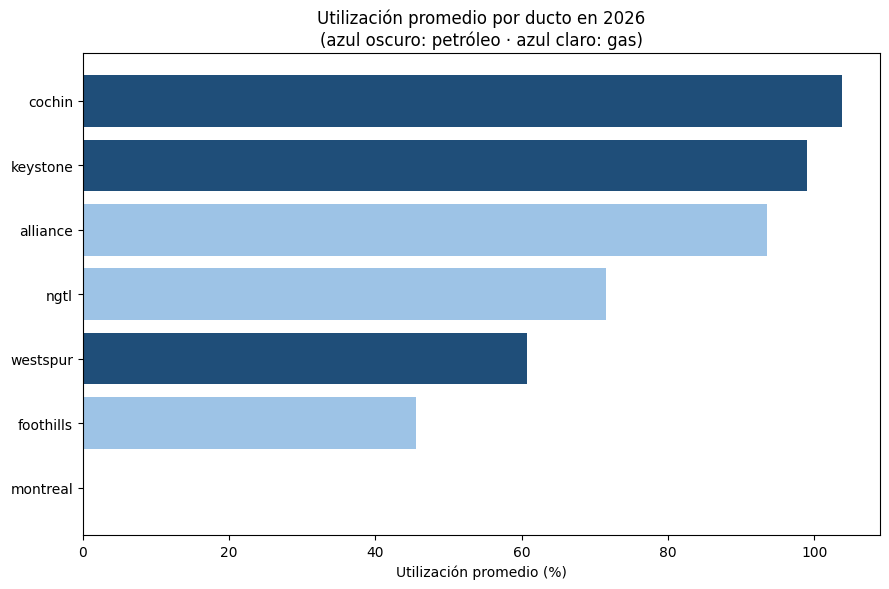

In [15]:
import matplotlib.pyplot as plt

consulta_1 = f"""
SELECT ducto, tipo, anio,
       ROUND(utilizacion_promedio * 100, 1) AS utilizacion_pct,
       ROUND(utilizacion_maxima * 100, 1)   AS utilizacion_max_pct,
       registros_sobre_90
FROM `{PROJECT_ID}.{DATASET}.resumen_anual`
WHERE anio = (SELECT MAX(anio) FROM `{PROJECT_ID}.{DATASET}.resumen_anual`)
  AND utilizacion_promedio BETWEEN 0 AND 1.5
ORDER BY utilizacion_pct DESC
"""
ranking = bq.query(consulta_1).to_dataframe()
display(ranking)

colores = ranking["tipo"].map({"petroleo": "#1f4e79", "gas": "#9dc3e6"}).tolist()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(ranking["ducto"], ranking["utilizacion_pct"], color=colores)
ax.invert_yaxis()
ax.set_xlabel("Utilización promedio (%)")
ax.set_ylabel("")
ax.set_title(f"Utilización promedio por ducto en {int(ranking['anio'].max())}\n(azul oscuro: petróleo · azul claro: gas)")
plt.tight_layout()
plt.show()

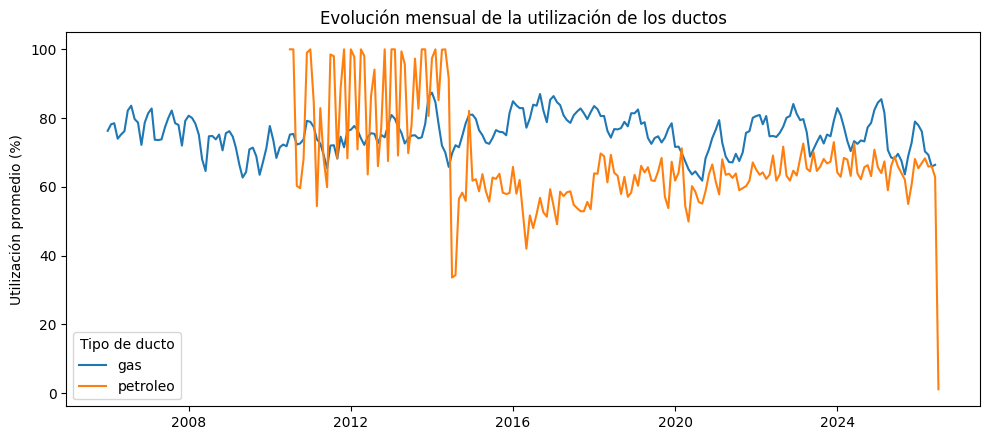

In [16]:
consulta_2 = f"""
SELECT periodo, tipo, ROUND(AVG(utilizacion) * 100, 1) AS utilizacion_pct
FROM `{PROJECT_ID}.{DATASET}.utilizacion_mensual`
WHERE utilizacion BETWEEN 0 AND 1.5
GROUP BY periodo, tipo
ORDER BY periodo
"""
tendencia = bq.query(consulta_2).to_dataframe()

tabla = tendencia.pivot(index="periodo", columns="tipo", values="utilizacion_pct")
ax = tabla.plot(figsize=(10, 4.5))
ax.set_ylabel("Utilización promedio (%)")
ax.set_xlabel("")
ax.set_title("Evolución mensual de la utilización de los ductos")
ax.legend(title="Tipo de ducto")
plt.tight_layout()
plt.show()

In [17]:
consulta_3 = f"""
WITH ultimo AS (
  SELECT MAX(periodo) AS fin FROM `{PROJECT_ID}.{DATASET}.utilizacion_mensual`
)
SELECT ducto, punto_clave, direccion,
       ROUND(AVG(utilizacion) * 100, 1) AS utilizacion_pct,
       COUNT(*) AS meses
FROM `{PROJECT_ID}.{DATASET}.utilizacion_mensual`, ultimo
WHERE periodo > DATE_SUB(fin, INTERVAL 12 MONTH)
  AND utilizacion BETWEEN 0 AND 1.5
GROUP BY ducto, punto_clave, direccion
ORDER BY utilizacion_pct DESC
LIMIT 10
"""
puntos_criticos = bq.query(consulta_3).to_dataframe()
display(puntos_criticos)

,ducto,punto_clave,direccion,utilizacion_pct,meses
0,ngtl,East Gate,east & southeast,103.0,11
1,ngtl,OSDA Kirby,east & north,102.3,11
2,alliance,Border,southeast,99.5,11
3,keystone,"International boundary at or near Haskett, Man...",south,99.4,11
4,southern-lights,system,north-west,93.2,2
5,alliance,Zone 2,southeast,92.0,11
6,cochin,Ft. Saskatchewan,west,89.2,11
7,ngtl,Upstream of James River,southeast & east,86.2,11
8,ngtl,OSDA Liege,east & north,79.4,11
9,ngtl,North and East,east & north,79.3,11


**¿Qué significan estos resultados para el bombeo?** Un punto clave con utilización alta durante muchos meses indica que las estaciones de bombeo o compresión de ese tramo trabajan cerca de su límite. Eso implica más consumo de energía, más desgaste de los equipos y menos margen ante una falla. Estos son justamente los puntos donde tendría más sentido aplicar mantenimiento predictivo u optimización energética.

## 10. Liberar recursos

Terminado el análisis, **borramos el clúster** para que no siga consumiendo crédito. Los datos quedan guardados en Cloud Storage y en BigQuery, que dentro de estos tamaños prácticamente no generan costo.

In [ ]:
!gcloud dataproc clusters delete {CLUSTER} --region={REGION} --quiet
!gcloud dataproc clusters list --region={REGION}

## 11. Conclusiones

1. **La nube permitió separar el almacenamiento del procesamiento.** Los datos viven en Cloud Storage y el clúster de Dataproc solo existió mientras procesaba. En un caso real con terabytes de datos de sensores, esta separación ahorra mucho dinero.
2. **La arquitectura por capas (bronce, plata y oro) ordenó el trabajo.** Siempre tuvimos los datos originales disponibles, y el formato Parquet hizo que las lecturas fueran más rápidas y livianas que con CSV.
3. **Spark resolvió la variedad de los datos.** Los archivos de petróleo y de gas tenían columnas distintas, y aun así se unieron en una sola tabla con un único programa.
4. **BigQuery facilitó el análisis.** Con SQL obtuvimos el ranking de ductos, la tendencia en el tiempo y los puntos más exigidos sin administrar servidores.
5. **Relación con el bombeo:** la utilización (caudal/capacidad) es una forma sencilla de detectar en qué tramos las estaciones de bombeo trabajan al límite, lo que ayuda a priorizar mantenimiento e inversiones.

**Limitaciones:** los datos públicos son mensuales o diarios y de tamaño pequeño; los datos de sensores en tiempo real de las empresas no son públicos. Además, la utilización depende de cómo cada empresa reporta su capacidad, por lo que la comparación entre ductos debe tomarse con cuidado.

*(Completar con los valores concretos observados en las gráficas: por ejemplo, el ducto con mayor utilización y cómo cambió la tendencia.)*

### Fuentes
- Canada Energy Regulator, *Pipeline Throughput and Capacity Data*, Gobierno de Canadá: https://open.canada.ca/data/en/dataset/dc343c43-a592-4a27-8ee7-c77df56afb34
- Documentación de Google Cloud Dataproc: https://cloud.google.com/dataproc/docs
- Documentación de BigQuery: https://cloud.google.com/bigquery/docs